In [ ]:

import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Artificial intelligence is transforming the world through smart machines.
AI helps doctors detect diseases and helps students learn faster.
Machine learning allows computers to discover patterns from data.
Natural language processing helps computers understand human language.
I believe AI can solve many real-world problems when developed responsibly."""

clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

split_words = clean_text.split()
nltk_words = word_tokenize(clean_text)

print("\nUsing split():\n", split_words)
print("\nUsing word_tokenize():\n", nltk_words)


stop_words = set(stopwords.words('english'))
filtered_words = [word for word in nltk_words
                  if word.isalpha() and word not in stop_words]

print("\nWords after Stopword Removal:\n", filtered_words)

freq_dist = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, frequency in freq_dist.most_common():
    print(word, ":", frequency)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Cleaned Text:
 artificial intelligence is transforming the world through smart machines
ai helps doctors detect diseases and helps students learn faster
machine learning allows computers to discover patterns from data
natural language processing helps computers understand human language
i believe ai can solve many realworld problems when developed responsibly

Word Tokens:
 ['artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'through', 'smart', 'machines', 'ai', 'helps', 'doctors', 'detect', 'diseases', 'and', 'helps', 'students', 'learn', 'faster', 'machine', 'learning', 'allows', 'computers', 'to', 'discover', 'patterns', 'from', 'data', 'natural', 'language', 'processing', 'helps', 'computers', 'understand', 'human', 'language', 'i', 'believe', 'ai', 'can', 'solve', 'many', 'realworld', 'problems', 'when', 'developed', 'responsibly']

Sentence Tokens:
 ['Artificial intelligence is transforming the world through smart machines.', 'AI helps doctors detect diseases and

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Artificial intelligence is transforming the world through smart machines.
AI helps doctors detect diseases and helps students learn faster.
Machine learning allows computers to discover patterns from data.
Natural language processing helps computers understand human language.
I believe AI can solve many real-world problems when developed responsibly."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic Words:\n", words)

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]
print("\nAfter Stopword Removal:\n", filtered_words)

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]
print("\nStemmed Words:\n", stemmed_words)

lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]
print("\nLemmatized Words:\n", lemmatized_words)

print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(f"{original:15} -> Stem: {stem:12} Lemma: {lemma}")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Alphabetic Words:
 ['artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'through', 'smart', 'machines', 'ai', 'helps', 'doctors', 'detect', 'diseases', 'and', 'helps', 'students', 'learn', 'faster', 'machine', 'learning', 'allows', 'computers', 'to', 'discover', 'patterns', 'from', 'data', 'natural', 'language', 'processing', 'helps', 'computers', 'understand', 'human', 'language', 'i', 'believe', 'ai', 'can', 'solve', 'many', 'real', 'world', 'problems', 'when', 'developed', 'responsibly']

After Stopword Removal:
 ['artificial', 'intelligence', 'transforming', 'world', 'smart', 'machines', 'ai', 'helps', 'doctors', 'detect', 'diseases', 'helps', 'students', 'learn', 'faster', 'machine', 'learning', 'allows', 'computers', 'discover', 'patterns', 'data', 'natural', 'language', 'processing', 'helps', 'computers', 'understand', 'human', 'language', 'believe', 'ai', 'solve', 'many', 'real', 'world', 'problems', 'developed', 'responsibly']

Stemmed Words:
 ['artifici', 'int

In [ ]:

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

documents = [
    "Artificial intelligence improves healthcare through disease detection and medical image analysis.",
    "Blockchain technology provides secure transactions and transparent digital records.",
    "Machine learning helps artificial intelligence analyze data and make accurate predictions."
]

count_vectorizer = CountVectorizer(stop_words='english')
bow_matrix = count_vectorizer.fit_transform(documents)

print("Bag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())


tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

features = tfidf_vectorizer.get_feature_names_out()

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray().round(3))

print("\nTop 3 TF-IDF Keywords:")
for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[::-1][:3]
    keywords = [(features[j], round(row[j], 3))
                for j in top_indices]
    print(f"Text {i + 1}: {keywords}")


Bag of Words Vocabulary:
['accurate' 'analysis' 'analyze' 'artificial' 'blockchain' 'data'
 'detection' 'digital' 'disease' 'healthcare' 'helps' 'image' 'improves'
 'intelligence' 'learning' 'machine' 'make' 'medical' 'predictions'
 'provides' 'records' 'secure' 'technology' 'transactions' 'transparent']

Bag of Words Matrix:
[[0 1 0 1 0 0 1 0 1 1 0 1 1 1 0 0 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1]
 [1 0 1 1 0 1 0 0 0 0 1 0 0 1 1 1 1 0 1 0 0 0 0 0 0]]

TF-IDF Matrix:
[[0.    0.35  0.    0.266 0.    0.    0.35  0.    0.35  0.35  0.    0.35
  0.35  0.266 0.    0.    0.    0.35  0.    0.    0.    0.    0.    0.
  0.   ]
 [0.    0.    0.    0.    0.354 0.    0.    0.354 0.    0.    0.    0.
  0.    0.    0.    0.    0.    0.    0.    0.354 0.354 0.354 0.354 0.354
  0.354]
 [0.33  0.    0.33  0.251 0.    0.33  0.    0.    0.    0.    0.33  0.
  0.    0.251 0.33  0.33  0.33  0.    0.33  0.    0.    0.    0.    0.
  0.   ]]

Top 3 TF-IDF Keywords:
Text 1: [('me

In [ ]:

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial intelligence enables machines to learn from data,
recognize patterns, make predictions, and automate complex tasks.
It is used in healthcare, education, robotics, and business."""

text2 = """Blockchain stores information in distributed digital records.
It uses cryptographic techniques to support secure transactions,
transparency, data integrity, and decentralized applications."""

def preprocess(text):
    return re.findall(r'\b[a-zA-Z]+\b', text.lower())

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Tokens 1:", tokens1)
print("Tokens 2:", tokens2)

set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nCommon Words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(
    tfidf_matrix[0:1], tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine, 4))

print("\nAnalysis:")
print("Jaccard measures overlap between unique words.")
print("Cosine measures similarity between TF-IDF vectors.")


Tokens 1: ['artificial', 'intelligence', 'enables', 'machines', 'to', 'learn', 'from', 'data', 'recognize', 'patterns', 'make', 'predictions', 'and', 'automate', 'complex', 'tasks', 'it', 'is', 'used', 'in', 'healthcare', 'education', 'robotics', 'and', 'business']
Tokens 2: ['blockchain', 'stores', 'information', 'in', 'distributed', 'digital', 'records', 'it', 'uses', 'cryptographic', 'techniques', 'to', 'support', 'secure', 'transactions', 'transparency', 'data', 'integrity', 'and', 'decentralized', 'applications']

Common Words: {'data', 'and', 'it', 'to', 'in'}
Jaccard Similarity: 0.125
Cosine Similarity: 0.0298

Analysis:
Jaccard measures overlap between unique words.
Cosine measures similarity between TF-IDF vectors.



Review 1: This phone has an excellent camera and amazing battery life.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review 2: The product is terrible, slow, and disappointing.
Polarity: -0.633
Subjectivity: 0.7
Sentiment: Negative

Review 3: The phone is okay and has average features.
Polarity: 0.175
Subjectivity: 0.45
Sentiment: Positive

Review 4: I love this phone because it is fast, beautiful, and reliable.
Polarity: 0.517
Subjectivity: 0.733
Sentiment: Positive

Review 5: The battery is poor and the screen quality is bad.
Polarity: -0.55
Subjectivity: 0.633
Sentiment: Negative


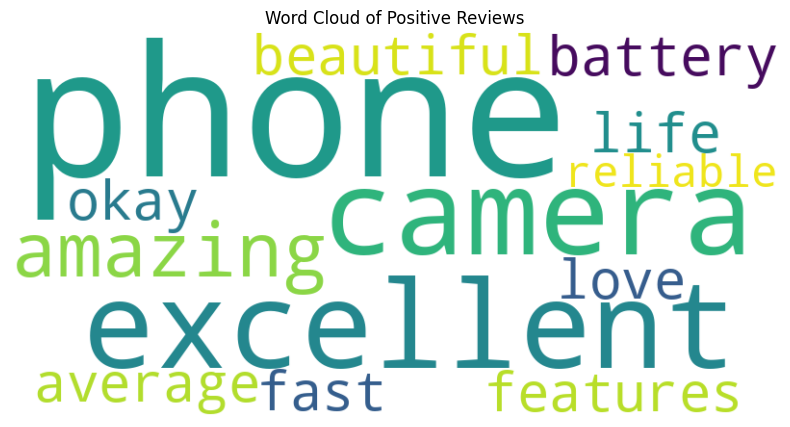

In [ ]:

# Install these libraries in Colab if needed:
# !pip install textblob wordcloud matplotlib

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Example product reviews
reviews = [
    "This phone has an excellent camera and amazing battery life.",
    "The product is terrible, slow, and disappointing.",
    "The phone is okay and has average features.",
    "I love this phone because it is fast, beautiful, and reliable.",
    "The battery is poor and the screen quality is bad."
]

positive_reviews = []

for i, review in enumerate(reviews, start=1):
    analysis = TextBlob(review).sentiment
    polarity = analysis.polarity
    subjectivity = analysis.subjectivity

    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"\nReview {i}: {review}")
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

    if sentiment == "Positive":
        positive_reviews.append(review)

if positive_reviews:
    combined_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        collocations=False
    ).generate(combined_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """
Artificial intelligence is changing the world through technology.
Machines can learn from data and identify useful patterns.
Students use technology to study difficult concepts and solve problems.
Doctors use intelligent systems to analyze medical images and support diagnosis.
Farmers can use digital tools to understand weather and improve crop production.
Language models can process text and generate meaningful sentences.
Machine learning helps computers make predictions from previous examples.
However, technology should be developed responsibly and safely.
People must protect private information and verify important results.
Education helps everyone understand the benefits and limitations of technology.
In the future, artificial intelligence may support research, healthcare, and education.
Human creativity and responsible decisions will remain important.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
print("Vocabulary Size:", total_words)

input_sequences = []

for line in text.lower().split("."):
    line = line.strip()
    if line:
        token_list = tokenizer.texts_to_sequences([line])[0]

        for i in range(1, len(token_list)):
            n_gram_sequence = token_list[:i + 1]
            input_sequences.append(n_gram_sequence)

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = input_sequences[:, :-1]

y = input_sequences[:, -1]

model = Sequential([
    Embedding(total_words, 32),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=150, verbose=0)

print("Model training completed.")

def generate_text(seed_text, next_words=15):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences(
            [seed_text]
        )[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        prediction = model.predict(token_list, verbose=0)
        predicted_id = int(np.argmax(prediction, axis=-1)[0])

        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted_id:
                output_word = word
                break

        if not output_word:
            break

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text:")
print(generate_text("technology", 15))
print(generate_text("artificial intelligence", 15))
print(generate_text("students", 15))


Vocabulary Size: 87
Model training completed.

Generated Text:
technology use to to study concepts and solve problems problems problems production production production production production
artificial intelligence is the the through through technology technology technology technology education safely safely problems problems problems
students use technology to to difficult concepts and solve problems problems problems production production production production
